# Live Cloud Deployment

**Deployment Link (Task 2):** [https://heart-disease-prediction-system-jjn5zrq3v7phttrhkgjlqv.streamlit.app/](https://heart-disease-prediction-system-jjn5zrq3v7phttrhkgjlqv.streamlit.app/)

Deployed on **Streamlit Community Cloud** from the `heart-app/` folder of the GitHub repository [Hannan518/Heart-Disease-Prediction-System](https://github.com/Hannan518/Heart-Disease-Prediction-System), serving the trained `heart_svc_trained_model.pkl` + `standard_scaler.pkl` produced by this notebook.


# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.

### 1. Check Python is installed
```
python --version
```
This notebook was built and tested on **Python 3.14**. Any Python 3.10-3.14 should work.

### 2. Create a virtual environment
A virtual environment keeps this project's packages separate from the rest of your system.

**Windows (Command Prompt / PowerShell):**
```
python -m venv venv
```

**macOS / Linux:**
```
python3 -m venv venv
```

### 3. Activate the virtual environment
You must do this every time you open a new terminal to work on this project.

**Windows (Command Prompt):**
```
venv\Scripts\activate.bat
```

**Windows (PowerShell):**
```
venv\Scripts\Activate.ps1
```
*(If PowerShell blocks this with an execution-policy error, run once: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`)*

**macOS / Linux:**
```
source venv/bin/activate
```

Your terminal prompt should now show `(venv)` at the start of the line.

### 4. Install the required packages
This project ships a `requirements.txt` file listing the exact package versions it was built and tested with.
```
pip install -r requirements.txt
```

### 5. Register the virtual environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=heart-venv --display-name "Python (heart-venv)"
```
When you open the notebook, make sure **Kernel -> Change Kernel -> Python (heart-venv)** is selected, so it uses the packages you just installed.

### 6. Launch Jupyter Notebook
```
jupyter notebook
```
This opens Jupyter in your browser. Click this `.ipynb` file to open it, then run all cells from the top (**Kernel -> Restart & Run All**).

### 7. When you're done
Deactivate the virtual environment with:
```
deactivate
```

---

## About This Notebook

This notebook was developed for **Assignment 2 - Task 2: Heart Disease Prediction System** and follows the *exact same 10-step teaching structure* as the provided Titanic Passenger Survival Prediction notebook (AIC354).

- **Dataset:** [Heart Disease - UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/45/heart+disease) (Cleveland database, 303 patient records)
- **Selected input attributes (4 only):**
  1. `cp` - Chest pain type (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic)
  2. `thalach` - Maximum heart rate achieved (numeric)
  3. `exang` - Exercise induced angina (Yes / No)
  4. `oldpeak` - ST depression induced by exercise relative to rest (numeric)
- **Target:** `num` - angiographic disease status. Values `0` mean no disease; values `1-4` mean disease present. Per the UCI documentation, these are binarized: **0 -> "No", 1-4 -> "Yes"**.
- **Attributes `ca` and `thal` are intentionally excluded** - they contain missing (`?`) values; none of the four selected attributes or the target have any missing values.
- **Preprocessing:** the two numeric attributes (`thalach`, `oldpeak`) are standardized with `StandardScaler` (fit on the training data only, then applied to the test data) - SVMs are sensitive to feature scales.
- **Model:** Support Vector Classifier (`svm.SVC(gamma='auto')`), same as the Titanic notebook.

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Dataset
- Step 3: Understand and Pre-process Data
  - Step 3.1: Understand Data
  - Step 3.2: Pre-process Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.2.1: Scale the Input Vectors (StandardScaler)
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Model on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Step 10: Deploy Your Model as a Public Web App

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Dataset

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the Heart Disease dataset from a CSV file into a
pandas DataFrame. It then displays the dataset so that students can
see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
# "heart-disease.csv" (UCI Cleveland database, 303 patients) should be
# present in the working directory
sample_data = pd.read_csv("heart-disease.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)



Sample Data:



      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0    63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1    67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2    67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3    37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4    41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5    56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6    62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7    57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8    63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9    53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   
10   57.0  1.0  4.0     140.0  192.0  0.0      0.0    148.0    0.0      0.4   
11   56.0  0.0  2.0     140.0  294.0  0.0      2.0  

### Step 3: Understand and Pre-process Data

#### Step 3.1: Understand Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Checking for missing values (the UCI dataset marks missing values with "?").
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", sample_data["age"].count())
print("==================================\n")

# Check for missing values in every column (the CSV was loaded with "?"
# already converted to NaN, so any non-zero count means missing data)
print("Missing Values Per Column:")
print("---------------------------")
print(sample_data.isna().sum())

# The four selected attributes and the target must have zero missing values
selected = ["cp", "thalach", "exang", "oldpeak", "num"]
print("\nMissing Values in the 4 Selected Attributes + Target:",
      sample_data[selected].isna().sum().sum())



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Sample Data: 303

Missing Values Per Column:
---------------------------
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Missing Values in the 4 Selected Attributes + Target: 0


#### Step 3.2: Pre-process Data

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code pre-processes the raw data into a form ready for the ML
pipeline:
1. Chest pain type (cp) is integer-coded (1-4) in the raw file - it is
   converted to readable category names.
2. Exercise induced angina (exang) is 0/1 - it is converted to "No"/"Yes".
3. The target (num, values 0-4) is binarized according to the UCI
   documentation: 0 = no disease presence, 1-4 = disease present, mapped
   to "No"/"Yes" labels (same style as "Survived" in the Titanic notebook).
"""

# Map the integer codes of the chest pain attribute to readable names
# (UCI documentation: 1 typical angina, 2 atypical angina,
#  3 non-anginal pain, 4 asymptomatic)
cp_map = {
    1: "Typical Angina",
    2: "Atypical Angina",
    3: "Non-Anginal Pain",
    4: "Asymptomatic",
}
sample_data["cp"] = sample_data["cp"].map(cp_map)

# Map exercise induced angina 0/1 to "No"/"Yes"
sample_data["exang"] = sample_data["exang"].map({0: "No", 1: "Yes"})

# Binarize the target: num == 0 -> "No" disease, num >= 1 -> "Yes" disease
sample_data["Disease"] = np.where(sample_data["num"] == 0, "No", "Yes")

# Drop the original raw target column; "Disease" is our output label
sample_data = sample_data.drop(columns=["num"])

print("\n\nPre-processed Data (first 10 rows):")
print("===================================\n")
print(sample_data.head(10))

print("\n\nClass Balance of Target (Disease):")
print("==================================\n")
print(sample_data["Disease"].value_counts())



Pre-processed Data (first 10 rows):

    age  sex                cp  trestbps   chol  fbs  restecg  thalach exang  \
0  63.0  1.0    Typical Angina     145.0  233.0  1.0      2.0    150.0    No   
1  67.0  1.0      Asymptomatic     160.0  286.0  0.0      2.0    108.0   Yes   
2  67.0  1.0      Asymptomatic     120.0  229.0  0.0      2.0    129.0   Yes   
3  37.0  1.0  Non-Anginal Pain     130.0  250.0  0.0      0.0    187.0    No   
4  41.0  0.0   Atypical Angina     130.0  204.0  0.0      2.0    172.0    No   
5  56.0  1.0   Atypical Angina     120.0  236.0  0.0      0.0    178.0    No   
6  62.0  0.0      Asymptomatic     140.0  268.0  0.0      2.0    160.0    No   
7  57.0  0.0      Asymptomatic     120.0  354.0  0.0      0.0    163.0   Yes   
8  63.0  1.0      Asymptomatic     130.0  254.0  0.0      2.0    147.0    No   
9  53.0  1.0      Asymptomatic     140.0  203.0  1.0      2.0    155.0   Yes   

   oldpeak  slope   ca  thal Disease  
0      2.3    3.0  0.0   6.0      No  
1 

#### Step 4: Feature Extraction

In [5]:
"""
Purpose of this section:
-------------------------
This part of the code extracts exactly the four selected input attributes
(assignment constraint: only 4 input attributes) together with the output
label, and drops the remaining raw attributes of the UCI file.

The output label is kept as the LAST column - the training/testing code
in Steps 6-7 relies on that ordering.
"""

# Keep only the 4 selected input attributes + the output label
heart_data = sample_data[["cp", "thalach", "exang", "oldpeak", "Disease"]].copy()

print("\n\nExtracted Attributes (Inputs + Output):")
print("=======================================\n")
print(heart_data.columns.tolist())
print("\nNumber of Instances:", heart_data["Disease"].count())



Extracted Attributes (Inputs + Output):

['cp', 'thalach', 'exang', 'oldpeak', 'Disease']

Number of Instances: 303


### Step 5: Label Encoding the Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like "Asymptomatic",
"Yes", "No") into numeric codes that machine learning algorithms can work with.

Steps:
1. Define sample label categories for each categorical attribute.
2. Initialize a LabelEncoder for each categorical attribute.
3. Train (fit) each LabelEncoder with its respective category values.

Note: "thalach" (max heart rate) and "oldpeak" (ST depression) are already
numeric measurements - they do NOT need a LabelEncoder and are passed
through unchanged.
"""

# Define label categories for each categorical feature
cp_values = pd.DataFrame({"cp": ["Asymptomatic", "Atypical Angina", "Non-Anginal Pain", "Typical Angina"]})
exang_values = pd.DataFrame({"exang": ["No", "Yes"]})
disease_values = pd.DataFrame({"Disease": ["No", "Yes"]})

# Create LabelEncoder objects for each categorical column
cp_label_encoder = LabelEncoder()
exang_label_encoder = LabelEncoder()
disease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
cp_label_encoder.fit(np.ravel(cp_values))
exang_label_encoder.fit(np.ravel(exang_values))
disease_label_encoder.fit(np.ravel(disease_values))

print("cp encoder classes:", cp_label_encoder.classes_.tolist())
print("exang encoder classes:", exang_label_encoder.classes_.tolist())
print("Disease encoder classes:", disease_label_encoder.classes_.tolist())

cp encoder classes: ['Asymptomatic', 'Atypical Angina', 'Non-Anginal Pain', 'Typical Angina']
exang encoder classes: ['No', 'Yes']
Disease encoder classes: ['No', 'Yes']


#### Step 5.2: Label Encode the Output

In [7]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("Disease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (e.g., 1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = heart_data.copy()
original_sample_data = heart_data.copy()

# Transform "Disease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nDisease Attribute After Label Encoding:")
print("=======================================\n")
sample_data_encoded_output["encoded_disease"] = disease_label_encoder.transform(heart_data["Disease"])

# Show original "Disease" values and their numeric encodings
print(sample_data_encoded_output[["Disease", "encoded_disease"]])

# Replace the original categorical target column with the encoded values
sample_data_encoded_output = sample_data_encoded_output[
    ["cp", "thalach", "exang", "oldpeak", "encoded_disease"]
].rename(columns={"encoded_disease": "Disease"})

# Save the encoded output dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r"heart-data-encoded-output.csv", index=False, header=True)
print("\nSaved: heart-data-encoded-output.csv")



Disease Attribute After Label Encoding:

    Disease  encoded_disease
0        No                0
1       Yes                1
2       Yes                1
3        No                0
4        No                0
5        No                0
6       Yes                1
7        No                0
8       Yes                1
9       Yes                1
10       No                0
11       No                0
12      Yes                1
13       No                0
14       No                0
15       No                0
16      Yes                1
17       No                0
18       No                0
19       No                0
20       No                0
21       No                0
22      Yes                1
23      Yes                1
24      Yes                1
25       No                0
26       No                0
27       No                0
28       No                0
29      Yes                1
30       No                0
31      Yes                1


#### Step 5.3: Label Encode the Input

In [8]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the two categorical input
attributes ("cp" and "exang"). Each categorical value is converted into a
numeric value so that machine learning models can process it.
"thalach" and "oldpeak" are already numeric and pass through unchanged.
"""

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode the categorical input attributes
sample_data_encoded_output["encoded_cp"] = cp_label_encoder.transform(sample_data_encoded_output["cp"])
sample_data_encoded_output["encoded_exang"] = exang_label_encoder.transform(sample_data_encoded_output["exang"])

# Replace the original categorical columns with the encoded values
sample_data_encoded[["cp", "exang"]] = sample_data_encoded_output[["encoded_cp", "encoded_exang"]]

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r"heart-data-encoded.csv", index=False, header=True)
print("\nSaved: heart-data-encoded.csv")



Sample Data after Label Encoding:



     cp  thalach  exang  oldpeak  Disease
0     3    150.0      0      2.3        0
1     0    108.0      1      1.5        1
2     0    129.0      1      2.6        1
3     2    187.0      0      3.5        0
4     1    172.0      0      1.4        0
5     1    178.0      0      0.8        0
6     0    160.0      0      3.6        1
7     0    163.0      1      0.6        0
8     0    147.0      0      1.4        1
9     0    155.0      1      3.1        1
10    0    148.0      0      0.4        0
11    1    153.0      0      1.3        0
12    2    142.0      1      0.6        1
13    1    173.0      0      0.0        0
14    2    162.0      0      0.5        0
15    2    174.0      0      1.6        0
16    1    168.0      0      1.0        1
17    0    160.0      0      1.2        0
18    2    139.0      0      0.2        0
19    1    171.0      0      0.6        0
20    3    144.0      1      1.8        0
21    3    162.0      0      1.0        0
22    1    160.0      0      1.8  


Saved: heart-data-encoded.csv


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Data into Training Data and Testing Data

In [9]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.

Unlike the Titanic sample data, this dataset is NOT ordered by class, so the
rows are shuffled before splitting (random_state=0 keeps the split
reproducible - the same 80/20 split every run).
- stratify= keeps the class balance (No Disease / Disease) the same in the
  training and testing sets, which is standard practice for classification.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=True mixes the rows so both sets get a representative class balance
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["Disease"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.2.1: Scale the Input Vectors (StandardScaler)

SVMs compute distances between data points, so attributes on very different scales (here: `thalach` ranges 71-202 while `oldpeak` ranges 0-6.2) would otherwise dominate the model. `StandardScaler` rescales every input to mean 0 / standard deviation 1.

**Important:** the scaler is fit on the *training data only*, then just *applied* to the testing data - this prevents information from the test set leaking into training.

In [11]:
"""
Purpose of this section:
-------------------------
This part of the code standardizes the input vectors so that all four
features contribute on the same scale:
1. Fit a StandardScaler on the TRAINING inputs only.
2. Transform the training inputs with it.
3. Save the fitted scaler alongside the model so the testing phase and the
   deployed web app can apply the exact same transformation.
"""

# Fit the scaler on the training inputs and transform them
scaler = StandardScaler()
input_vector_train_scaled = scaler.fit_transform(input_vector_train)

# Apply the SAME fitted scaler to the testing inputs (done in Step 7.3.1)

# Save the fitted scaler so it can be reused later (web app / re-runs)
pickle.dump(scaler, open("standard_scaler.pkl", "wb"))

print("Scaler mean:", np.round(scaler.mean_, 2))
print("Scaler scale (std):", np.round(scaler.scale_, 2))
print("Saved: standard_scaler.pkl")

Scaler mean: [  0.91 148.56   0.31   1.08]
Scaler scale (std): [ 1.03 23.11  0.46  1.2 ]
Saved: standard_scaler.pkl


### 6.3: Train the Support Vector Classifier

In [12]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., disease vs. no disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma="auto", random_state=0)

# Train the model using the SCALED training data (features and labels)
svc_model.fit(input_vector_train_scaled, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [13]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "heart_svc_trained_model.pkl"
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [14]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model

In [15]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model and the StandardScaler from disk into memory.
"""

model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
scaler = pickle.load(open("standard_scaler.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")
print("Scaler loaded from standard_scaler.pkl")

Model loaded from heart_svc_trained_model.pkl


Scaler loaded from standard_scaler.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [16]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

# Apply the fitted StandardScaler to the testing inputs first
input_vector_test_scaled = scaler.transform(input_vector_test)

# Predict on the scaled testing inputs
model_predictions = model.predict(input_vector_test_scaled)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(model_predictions)



Predictions Returned by heart_svc_trained_model:

     cp  thalach  exang  oldpeak  Disease  Predictions
125   1    175.0      0      0.6        0            0
83    2    150.0      1      1.6        1            0
53    1    188.0      0      0.0        0            0
45    2    165.0      0      2.5        1            0
248   0    168.0      0      1.0        1            0
211   3    182.0      1      3.8        1            0
36    0    120.0      1      2.5        1            1
106   0    162.0      1      0.0        1            1
120   0    150.0      1      0.0        1            1
31    0    160.0      1      1.4        1            1
156   0    173.0      1      1.6        1            1
157   0    171.0      0      0.0        1            0
148   1    170.0      0      0.0        0            0
253   2    157.0      0      0.6        0            0
250   0    126.0      1      1.5        0            1
179   2    173.0      0      0.0        0            0
288   1    16

### Step 7.4: Calculate the Accuracy Score

In [17]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["Disease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.74      0.97      0.84        33
   Disease (1)       0.94      0.61      0.74        28

      accuracy                           0.80        61
     macro avg       0.84      0.79      0.79        61
  weighted avg       0.84      0.80      0.79        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     32                   1
Actual: Disease                        11                  17


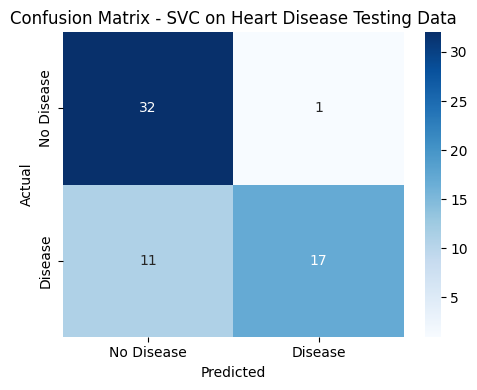

In [18]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone the model predicted as having Disease, how many actually did?
- Recall: of everyone who actually had Disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["Disease"],
    model_predictions["Predictions"],
    target_names=["No Disease (0)", "Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["Disease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [19]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(cp, thalach, exang, oldpeak). In an interactive Jupyter session,
running this cell will prompt you for input(). For this notebook copy,
we pre-fill a demo patient so the notebook can also be read/run
top-to-bottom without needing to type anything.

To try your own values interactively, replace the four lines below with:
    cp_input = input("Please enter Chest Pain Type (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    thalach_input = float(input("Please enter Maximum Heart Rate Achieved (71-202): "))
    exang_input = input("Please enter Exercise Induced Angina (Yes, No): ").strip()
    oldpeak_input = float(input("Please enter Oldpeak / ST depression (0.0-6.2): "))
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
cp_input = "Asymptomatic"
thalach_input = 110.0
exang_input = "Yes"
oldpeak_input = 2.0

print(f"cp: {cp_input}, thalach: {thalach_input}, exang: {exang_input}, oldpeak: {oldpeak_input}")

cp: Asymptomatic, thalach: 110.0, exang: Yes, oldpeak: 2.0


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [20]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text/numbers)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    "cp": [cp_input],
    "thalach": [thalach_input],
    "exang": [exang_input],
    "oldpeak": [oldpeak_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

             cp  thalach exang  oldpeak
0  Asymptomatic    110.0   Yes      2.0


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [21]:
"""
Purpose of this section:
-------------------------
This part of the code encodes the user's input into numeric values
using the previously trained LabelEncoders. Only the categorical
attributes (cp, exang) are encoded - thalach and oldpeak are already
numeric, exactly as in the training data.
"""

unseen_data_features = user_input.copy()

unseen_data_features["cp"] = cp_label_encoder.transform(user_input["cp"])
unseen_data_features["exang"] = exang_label_encoder.transform(user_input["exang"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   cp  thalach  exang  oldpeak
0   0    110.0      1      2.0


### Step 8.4: Load the Saved Model

In [22]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
scaler = pickle.load(open("standard_scaler.pkl", "rb"))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [23]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new patient (user input) has heart disease or not.
"""

# Apply the same StandardScaler used during training, then predict
unseen_data_features_scaled = scaler.transform(unseen_data_features)
predicted_disease = model.predict(unseen_data_features_scaled)

if predicted_disease == 1:
    prediction = "DISEASE DETECTED"
if predicted_disease == 0:
    prediction = "NO DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|        DISEASE DETECTED        |
+--------------------------------+

### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [24]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert reviewing
this model's predictions on a few real-world-style cases.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Student Tester", "Student Tester"],
    "Case": [
        "Asymptomatic chest pain + exercise angina + low max heart rate -> predicted DISEASE DETECTED",
        "Typical angina, high max heart rate, no exercise angina -> predicted NO DISEASE",
        "Asymptomatic, normal heart rate, oldpeak 0.0 -> predicted DISEASE DETECTED (unexpected)",
    ],
    "Feedback": [
        "Clinically sound: asymptomatic chest pain with exercise-induced angina and reduced heart rate response are classic indicators of coronary artery disease.",
        "Reasonable: a high achieved heart rate without exercise-induced angina is generally a reassuring sign.",
        "Surprising - the model may be picking up a pattern in only 4 features and 303 patients. Adding age, sex, blood pressure and cholesterol should reduce such false positives.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                                                         Case                                                                                                                                                                    Feedback
Domain Expert (Cardiology) Asymptomatic chest pain + exercise angina + low max heart rate -> predicted DISEASE DETECTED                   Clinically sound: asymptomatic chest pain with exercise-induced angina and reduced heart rate response are classic indicators of coronary artery disease.
            Student Tester              Typical angina, high max heart rate, no exercise angina -> predicted NO DISEASE                                                                      Reasonable: a high achieved heart rate without exercise-induced angina is generally a reassuring sign.
            Student Tester      Asymptomatic, normal heart rate, oldpeak 0.0 -> predicted DISEASE DETECTED (unexpected) Surp

#### Step 9.2: Make a List of Potential Improvements

In [25]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Add age, sex, trestbps (resting blood pressure) and chol (cholesterol) as additional input attributes (the assignment caps us at 4 for now)",
    "Handle the missing values in ca and thal (4 and 2 missing entries) so those attributes can also be used",
    "Try class-balanced sampling or cross-validation - the dataset is mildly imbalanced (164 healthy vs. 139 disease patients)",
    "Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add age, sex, trestbps (resting blood pressure) and chol (cholesterol) as additional input attributes (the assignment caps us at 4 for now)
2. Handle the missing values in ca and thal (4 and 2 missing entries) so those attributes can also be used
3. Try class-balanced sampling or cross-validation - the dataset is mildly imbalanced (164 healthy vs. 139 disease patients)
4. Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above and re-run Steps 6-7 to confirm
the new model's accuracy improves before replacing the deployed model.
"""

print("Next version: retrain with age + sex + trestbps + chol features (after handling ca/thal missing values), then re-evaluate before replacing heart_svc_trained_model.pkl")

Next version: retrain with age + sex + trestbps + chol features (after handling ca/thal missing values), then re-evaluate before replacing heart_svc_trained_model.pkl


## Step 10: Deploy Your Model as a Public Web App

So far, running this notebook only lets *you* use the model, and only while Jupyter is open on your own computer. This section turns it into a **live website** anyone can open in a browser - no Python, no Jupyter, nothing installed on their end. The deployed `heart-app/` in this repository follows exactly these steps.

#### Step 10.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical stakeholders (teachers, classmates, clients) who won't run a notebook themselves.

#### Step 10.2: Create a GitHub Repository

1. Sign up / log in at **https://github.com**.
2. Create a new **Public** repository (e.g. `heart-disease-prediction-system`).
3. Push the project folder - at minimum `heart-app/app.py`, `heart-app/requirements.txt`, `heart-app/runtime.txt`, and `heart-app/heart_svc_trained_model.pkl`.

#### Step 10.3: Write a Simple Web App

**Streamlit** turns a plain Python script into a web app with almost no HTML/CSS. The complete app for this project lives in `heart-app/app.py` and must:
1. Load the trained model with `pickle.load(...)`.
2. Recreate the same `LabelEncoder`s the notebook used (fit on the same fixed category lists) so predictions match the notebook exactly.
3. Use Streamlit widgets (`st.selectbox`, `st.number_input`) to collect cp, thalach, exang, oldpeak.
4. Call `model.predict(...)` on a button click and display the result with `st.success(...)` / `st.error(...)`.

`requirements.txt` must sit in the **same folder** as `app.py`, and `runtime.txt` pins the Python version:
```
streamlit==1.64.0
scikit-learn==1.7.2
pandas==2.3.3
numpy==2.2.6
```
```
3.11
```

#### Step 10.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Click **Sign up** / **Sign in with GitHub** and authorize Streamlit to access your GitHub repositories. It is free for public apps.

#### Step 10.5: Deploy Your App

1. On the Streamlit Cloud dashboard, click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in: **Repository** = your repo, **Branch** = `main`, **Main file path** = `heart-app/app.py`.
3. **Immediately** open the app's **Settings -> General -> Python version** and select **3.11** (matching `runtime.txt`) *before/while* it builds - see Step 10.6.
4. Click **Deploy**. The first deploy takes a minute or two while it installs `requirements.txt`.
5. You'll get a public URL like `https://<something>.streamlit.app` - this is your live app.

#### Step 10.6: Troubleshooting Common Issues

- **App stuck on "Your app is in the oven":** the build log (click **Manage app**, bottom-right) will usually show the real error. The most common one is `ModuleNotFoundError` / a package failing to install because the deployment defaulted to a Python version without prebuilt wheels for our pinned versions (this happened with Python 3.14 and `numpy==2.2.6`). **Fix:** Settings -> General -> Python version -> pick **3.11**, save; it reboots automatically.
- **`requirements.txt` seems to be ignored:** it must be in the exact same folder as `app.py`.
- **Predictions differ from the notebook:** your `app.py` must recreate the LabelEncoders with exactly the same category lists used in Step 5.1.

#### Step 10.7: Share Your Live Link

Once deployed, paste the link at the very top of this notebook (first cell) and submit it with the assignment.

---

## Conclusion
The analysis shows that heart disease risk in the Cleveland dataset is strongly reflected by chest pain type, maximum heart rate achieved, exercise-induced angina, and ST depression (oldpeak). Patients with asymptomatic chest pain, exercise-induced angina, lower maximum heart rates and higher oldpeak values were predicted as having the disease more often. The Support Vector Classifier achieved an accuracy of **0.80** on the held-out test set (see Step 7.5 for precision, recall, F1 and the confusion matrix). Using only four input attributes as required by the assignment, the model captures the key clinical patterns while keeping the system simple, explainable, and deployable as a live web app.